In [7]:
from PyQt6.QtWidgets import (
    QApplication, QWidget, QPushButton, QVBoxLayout, QLabel, QFileDialog, QHBoxLayout, QSlider
)
from PyQt6.QtMultimedia import QMediaPlayer, QAudioOutput
from PyQt6.QtCore import QUrl, Qt
import sys
import os

class SoundPlayer(QWidget):
    def __init__(self):
        super().__init__()
        self.init_ui()

    def init_ui(self):
        self.setWindowTitle("Sound Player")
        self.setGeometry(300, 300, 400, 200)

        # Media player setup
        self.media_player = QMediaPlayer()
        self.audio_output = QAudioOutput()
        self.media_player.setAudioOutput(self.audio_output)

        # Layouts
        layout = QVBoxLayout()
        button_layout = QHBoxLayout()

        # Buttons
        self.open_button = QPushButton("Open File")
        self.play_button = QPushButton("Play")
        self.pause_button = QPushButton("Pause")
        self.skip_backward_button = QPushButton("<< 5s")
        self.skip_forward_button = QPushButton("5s >>")

        # Slider
        self.position_slider = QSlider(Qt.Orientation.Horizontal)
        self.position_slider.setRange(0, 100)
        self.position_slider.setValue(0)

        # Add buttons and slider to layout
        button_layout.addWidget(self.open_button)
        button_layout.addWidget(self.play_button)
        button_layout.addWidget(self.pause_button)
        button_layout.addWidget(self.skip_backward_button)
        button_layout.addWidget(self.skip_forward_button)

        layout.addLayout(button_layout)
        layout.addWidget(self.position_slider)

        # Status Label
        self.status_label = QLabel("No file loaded")
        layout.addWidget(self.status_label)

        self.setLayout(layout)

        # Connect buttons to functions
        self.open_button.clicked.connect(self.open_file)
        self.play_button.clicked.connect(self.play_audio)
        self.pause_button.clicked.connect(self.pause_audio)
        self.skip_backward_button.clicked.connect(self.skip_backward)
        self.skip_forward_button.clicked.connect(self.skip_forward)
        self.position_slider.sliderMoved.connect(self.set_position)

        # Connect media player signals
        self.media_player.positionChanged.connect(self.update_slider)
        self.media_player.durationChanged.connect(self.update_slider_range)

    def open_file(self):
        file_path, _ = QFileDialog.getOpenFileName(
            self, "Open Audio File", "", "Audio Files (*.mp3 *.wav *.ogg)"
        )

        if file_path:
            self.media_player.setSource(QUrl.fromLocalFile(file_path))
            self.status_label.setText(f"Loaded: {os.path.basename(file_path)}")

    def play_audio(self):
        self.media_player.play()
        self.status_label.setText("Playing")

    def pause_audio(self):
        self.media_player.pause()
        self.status_label.setText("Paused")

    def skip_backward(self):
        current_position = self.media_player.position()
        self.media_player.setPosition(max(0, current_position - 5000))  # Skip 5s back

    def skip_forward(self):
        current_position = self.media_player.position()
        self.media_player.setPosition(current_position + 5000)  # Skip 5s forward

    def update_slider(self, position):
        self.position_slider.setValue(position)

    def update_slider_range(self, duration):
        self.position_slider.setRange(0, duration)

    def set_position(self, position):
        self.media_player.setPosition(position)

if "app" in locals():
    del app
if __name__ == "__main__":
    app = QApplication(sys.argv)
    player = SoundPlayer()
    player.show()
    sys.exit(app.exec())

SystemExit: 0

d:\Software\anaconda3\Lib\site-packages\IPython\core\interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


SystemExit: 0

d:\Software\anaconda3\Lib\site-packages\IPython\core\interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


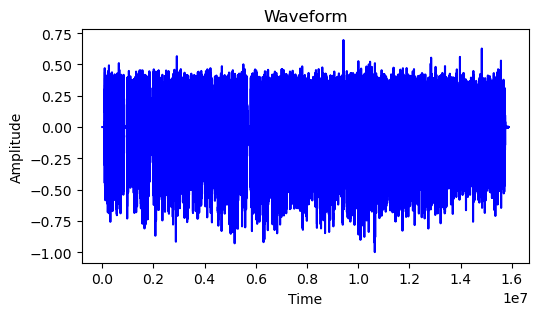

In [9]:
from PyQt6.QtWidgets import (
    QApplication, QWidget, QPushButton, QVBoxLayout, QLabel, QFileDialog, QHBoxLayout, QSlider
)
from PyQt6.QtMultimedia import QMediaPlayer, QAudioOutput
from PyQt6.QtCore import QUrl, Qt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
import matplotlib.pyplot as plt
from pydub import AudioSegment
import numpy as np
import sys
import os

class SoundPlayer(QWidget):
    def __init__(self):
        super().__init__()
        self.init_ui()

    def init_ui(self):
        self.setWindowTitle("Sound Player")
        self.setGeometry(300, 300, 600, 400)

        # Media player setup
        self.media_player = QMediaPlayer()
        self.audio_output = QAudioOutput()
        self.media_player.setAudioOutput(self.audio_output)

        # Layouts
        layout = QVBoxLayout()
        button_layout = QHBoxLayout()

        # Buttons
        self.open_button = QPushButton("Open File")
        self.play_button = QPushButton("Play")
        self.pause_button = QPushButton("Pause")
        self.skip_backward_button = QPushButton("<< 5s")
        self.skip_forward_button = QPushButton("5s >>")

        # Slider
        self.position_slider = QSlider(Qt.Orientation.Horizontal)
        self.position_slider.setRange(0, 100)
        self.position_slider.setValue(0)

        # Add buttons and slider to layout
        button_layout.addWidget(self.open_button)
        button_layout.addWidget(self.play_button)
        button_layout.addWidget(self.pause_button)
        button_layout.addWidget(self.skip_backward_button)
        button_layout.addWidget(self.skip_forward_button)

        layout.addLayout(button_layout)
        layout.addWidget(self.position_slider)

        # Status Label
        self.status_label = QLabel("No file loaded")
        layout.addWidget(self.status_label)

        # Waveform Display
        self.figure, self.ax = plt.subplots()
        self.canvas = FigureCanvas(self.figure)
        layout.addWidget(self.canvas)

        self.setLayout(layout)

        # Connect buttons to functions
        self.open_button.clicked.connect(self.open_file)
        self.play_button.clicked.connect(self.play_audio)
        self.pause_button.clicked.connect(self.pause_audio)
        self.skip_backward_button.clicked.connect(self.skip_backward)
        self.skip_forward_button.clicked.connect(self.skip_forward)
        self.position_slider.sliderMoved.connect(self.set_position)

        # Connect media player signals
        self.media_player.positionChanged.connect(self.update_slider)
        self.media_player.durationChanged.connect(self.update_slider_range)

    def open_file(self):
        file_path, _ = QFileDialog.getOpenFileName(
            self, "Open Audio File", "", "Audio Files (*.mp3 *.wav *.ogg)"
        )

        if file_path:
            self.media_player.setSource(QUrl.fromLocalFile(file_path))
            self.status_label.setText(f"Loaded: {os.path.basename(file_path)}")
            self.plot_waveform(file_path)

    def plot_waveform(self, file_path):
        audio = AudioSegment.from_file(file_path)
        samples = np.array(audio.get_array_of_samples())

        # Normalize samples for better visualization
        samples = samples / np.max(np.abs(samples))
        self.ax.clear()
        self.ax.plot(samples, color="blue")
        self.ax.set_title("Waveform")
        self.ax.set_xlabel("Time")
        self.ax.set_ylabel("Amplitude")
        self.canvas.draw()

    def play_audio(self):
        self.media_player.play()
        self.status_label.setText("Playing")

    def pause_audio(self):
        self.media_player.pause()
        self.status_label.setText("Paused")

    def skip_backward(self):
        current_position = self.media_player.position()
        self.media_player.setPosition(max(0, current_position - 5000))  # Skip 5s back

    def skip_forward(self):
        current_position = self.media_player.position()
        self.media_player.setPosition(current_position + 5000)  # Skip 5s forward

    def update_slider(self, position):
        self.position_slider.setValue(position)

    def update_slider_range(self, duration):
        self.position_slider.setRange(0, duration)

    def set_position(self, position):
        self.media_player.setPosition(position)
        
if "app" in locals():
    del app
if __name__ == "__main__":
    app = QApplication(sys.argv)
    player = SoundPlayer()
    player.show()
    sys.exit(app.exec())